# 스레드 재개와 대화 이어가기

**이 노트북에서 할 일**

1. 메시지 칸을 둔 그래프에 SQLite 체크포인터를 붙여, 한 스레드로 질문 두 개를 넣습니다.
2. 첫 연결을 닫아 첫 체크포인터와 첫 그래프를 못 쓰게 한 뒤, 모두 새로 만듭니다.
3. 새 그래프로 같은 스레드에 셋째 질문을 넣어, 앞 대화가 이어지는지 확인합니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
01절처럼 매번 같은 값을 내는 우리 노드로, 저장된 값이 맞는지 출력으로 가릅니다.
답 메시지의 글도 모델이 쓴 글이 아니라, 노드 함수가 질문 수를 세어 만든 글입니다.

노트북은 빈 임시 폴더를 만들어 그 폴더에서 실행합니다.
체크포인트를 담는 SQLite 파일은 이 임시 폴더에 생기고, 실습 폴더에는 파일을 남기지 않습니다.
읽어 오는 자료 파일은 없습니다.
교재 출력을 만든 실행에서는 노트북 전체가 5초 안에 끝났습니다.
설치 셀에 걸리는 시간은 네트워크에 따라 달라집니다.

**기준 버전** — 첫 셀에서 패키지 셋을 설치합니다.
그래프는 langgraph 1.2.11입니다.
SQLite 체크포인터는 langgraph-checkpoint-sqlite 3.0.3에 들어 있습니다.
메시지 클래스가 든 langchain-core의 판은 1.6.2입니다.

교재 출력은 Linux의 Python 3.12.13과, 그 Python에 들어 있는 SQLite 3.53.1로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~6절을 읽습니다.
첫 연결로 대화를 쌓고, 연결을 닫은 뒤 새 그래프로 이어 가는 자리입니다.
7~9절은 스레드 이름과 파일 이름을 바꿔 보고, 연결을 닫는 다른 모양을 보는 자리입니다.
이 부분은 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch23-persistence`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 맨 위 칸 첫 객체 5절에서 연결을 닫음 안에는 초록 상자 첫 연결 first_conn 아래 회색 상자 첫 체크포인터와 첫 그래프 질문 둘을 넣음이 있습니다. 이 칸에서 체크포인트를 씀이라고 적힌 화살표가 초록 상자 파일 chat.sqlite 스레드 conversation-a 체크포인트 여섯 메시지 넷으로 갑니다. 파일에서 마지막 체크포인트를 읽음이라고 적힌 화살표가 칸 새 객체 6절에서 새로 만듦으로 갑니다. 그 칸 안에는 초록 상자 새 연결 second_conn 아래 회색 상자 새 체크포인터와 새 그래프 셋째 질문을 넣음이 있습니다. 맨 아래 노란 상자에는 메시지 여섯 3번째 질문을 받았습니다 체크포인트 아홉이 적힌 그림](attachment:03-1-닫아도-파일에-남는-대화.png)

위에서 아래로 읽습니다.
초록 상자는 연결과 파일이고, 회색 상자는 라이브러리의 체크포인터와 그래프입니다.
위 칸의 객체는 노트북 5절에서 닫혀 더 쓸 수 없고, 아래 칸의 객체는 6절에서 새로 만들었습니다.
두 칸을 잇는 것은 파일 하나뿐이고, 맨 아래 노란 상자는 6절 출력입니다.
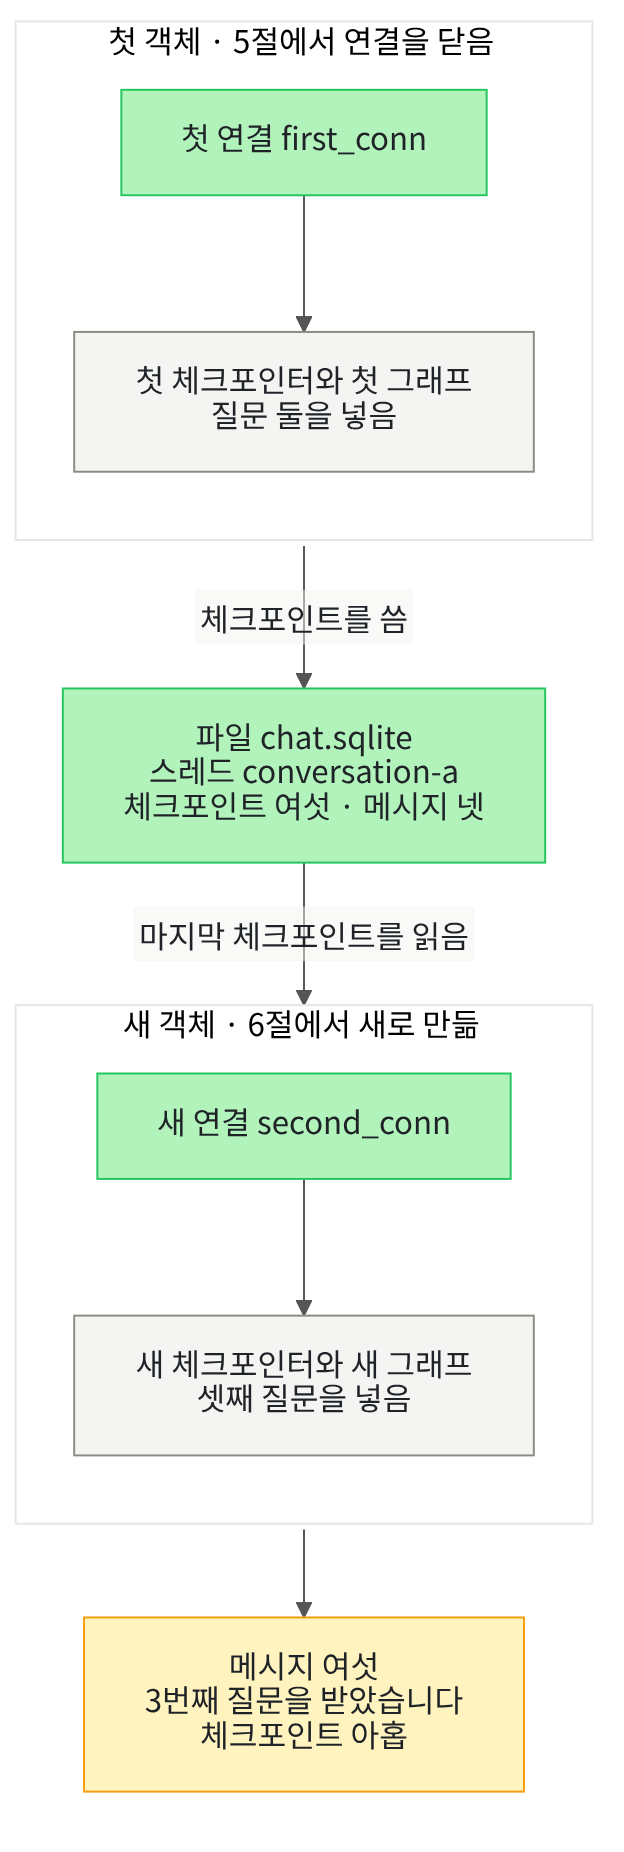

## 1. 준비

01절의 체크포인터 `InMemorySaver`는 이 프로그램의 메모리에만 저장했습니다.
02절에서는 PostgreSQL 표에 저장했지만, 새 연결로 스레드를 이어 가 보지는 않았습니다.
이 절은 체크포인트를 SQLite 파일에 쓰고, 연결과 그래프 객체를 모두 새로 만들어 같은 대화를 이어 갑니다.
대화는 Ch 13 04절의 메시지 칸에 사람 메시지와 AI 메시지로 쌓습니다.

첫 셀은 패키지 셋을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11" "langgraph-checkpoint-sqlite==3.0.3" "langchain-core==1.6.2"
from importlib.metadata import version

print("langgraph:", version("langgraph"))
print("langgraph-checkpoint-sqlite:", version("langgraph-checkpoint-sqlite"))
print("langchain-core:", version("langchain-core"))

Note: you may need to restart the kernel to use updated packages.
langgraph: 1.2.11
langgraph-checkpoint-sqlite: 3.0.3
langchain-core: 1.6.2


**결과 읽기** — 출력 줄 `langgraph: 1.2.11`·`langgraph-checkpoint-sqlite: 3.0.3`·`langchain-core: 1.6.2`가 보입니다.
세 판 모두 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-25에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
모듈 `sqlite3`는 Ch 4 03절에서 SQLite 파일을 다룰 때 쓴 모듈입니다.
메시지 클래스 셋은 Ch 13 04절과 같지만, 이 절은 클래스가 원래 들어 있는 langchain-core에서 가져옵니다.
메시지 리듀서 `add_messages`는 그 절처럼 langgraph에서 가져옵니다.
새로 가져오는 이름은 체크포인터 `SqliteSaver` 하나이고, 뜻은 3절에서 풉니다.

In [2]:
# SQLite 모듈(Ch 4 03절)·그래프 이름(Ch 13 01절)·메시지 이름(Ch 13 04절)에, SQLite 체크포인터를 더해 가져옵니다
import sqlite3
from typing import Annotated
from typing_extensions import TypedDict
from langchain_core.messages import AIMessage, AnyMessage, HumanMessage
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
# 체크포인트를 SQLite 파일의 표에 쓰는 체크포인터입니다
from langgraph.checkpoint.sqlite import SqliteSaver

print("이 절에서 새로 가져온 이름:", "SqliteSaver")
# sqlite_version에는 Python에 들어 있는 SQLite의 판 번호 글이 들어 있습니다
print("SQLite 판:", sqlite3.sqlite_version)

이 절에서 새로 가져온 이름: SqliteSaver
SQLite 판: 3.53.1


**결과 읽기** — 출력 줄 `이 절에서 새로 가져온 이름: SqliteSaver`와 `SQLite 판: 3.53.1`이 보입니다.
체크포인터 `SqliteSaver`는 첫 셀에서 설치한 langgraph-checkpoint-sqlite에 들어 있습니다.
SQLite 판 번호는 Python에 들어 있는 SQLite의 판이라, 컴퓨터에 따라 다르게 나올 수 있습니다.

다음 셀은 01절처럼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다.
이 절의 SQLite 파일은 모두 이 임시 폴더에 생깁니다.

In [3]:
# 파일이 생기는지 볼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다(Ch 4 03절과 같은 모양)
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고, 그 폴더의 위치를 글로 내놓습니다
practice_folder = tempfile.mkdtemp(prefix="ch23-03-")
# chdir()는 터미널의 cd처럼 현재 작업 폴더를 옮깁니다
os.chdir(practice_folder)
print("임시 폴더 이름에 ch23-03-이 들어 있는가:", "ch23-03-" in practice_folder)
print("현재 작업 폴더의 파일:", os.listdir())

임시 폴더 이름에 ch23-03-이 들어 있는가: True
현재 작업 폴더의 파일: []


**결과 읽기** — 출력 줄 `임시 폴더 이름에 ch23-03-이 들어 있는가: True`로, 이 절의 폴더를 만들었습니다.
출력 줄 `현재 작업 폴더의 파일: []`로, 빈 폴더에서 시작합니다.

## 2. 메시지 칸과 노드

이 절의 그래프는 질문 하나를 받을 때마다 답 메시지 하나를 붙이는 작은 그래프입니다.
다음 셀은 상태 형식입니다.
칸은 Ch 13 04절의 메시지 칸 `messages` 하나이고, 메시지 리듀서 `add_messages`를 적습니다.
번호를 적지 않은 메시지는 리듀서가 새 번호를 붙여, 목록 뒤에 이어 붙입니다.
칸 구성이 Ch 13 04절과 달라, Ch 13 약속대로 상태 형식 이름을 새로 붙였습니다.

In [4]:
# 메시지 칸 하나에 메시지 리듀서를 적은 상태 형식을 만듭니다(Ch 13 04절 모양)
class ConversationState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
표시 `Annotated`로 칸 `messages`에 메시지 리듀서를 적었습니다.

다음 셀은 노드 함수입니다.
메시지 칸에서 사람 메시지가 몇 개인지 세어, 「N번째 질문을 받았습니다」라는 글을 만듭니다.
그 글을 AI 메시지 하나에 담아 냅니다.
이 글은 모델이 쓴 답이 아니라, 우리 코드가 센 수로 만든 글입니다.

In [5]:
# 메시지 칸에서 사람 메시지 수를 세어, 몇 번째 질문인지 적은 AI 메시지 하나를 냅니다
def reply(state):
    question_count = 0
    for message in state["messages"]:
        if type(message).__name__ == "HumanMessage":
            question_count = question_count + 1
    # 모델을 부르지 않고, 센 수로 코드가 답 글을 만듭니다
    answer_text = str(question_count) + "번째 질문을 받았습니다"
    return {"messages": [AIMessage(content=answer_text)]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
메시지의 종류는 01절처럼 `type(message).__name__`으로 읽고, 그 이름이 `HumanMessage`일 때만 셉니다.
메시지 칸에 규칙을 적었으므로, 노드는 새 AI 메시지 하나만 냅니다.

다음 셀은 01절처럼 이 노드 함수를 그래프 없이 직접 불러 봅니다.
손으로 만든 상태에는 사람 메시지 하나만 있습니다.

In [6]:
# 노드 함수도 보통 함수입니다. 사람 메시지 하나를 담은 상태를 손으로 만들어 직접 불러 봅니다
hand_state = {"messages": [HumanMessage(content="대출 기간은 며칠인가요?")]}
hand_update = reply(hand_state)
hand_message = hand_update["messages"][0]
print("낸 메시지의 종류:", type(hand_message).__name__)
print("낸 메시지의 글:", hand_message.text)

낸 메시지의 종류: AIMessage
낸 메시지의 글: 1번째 질문을 받았습니다


**결과 읽기** — 출력 줄 `낸 메시지의 종류: AIMessage`와 `낸 메시지의 글: 1번째 질문을 받았습니다`입니다.
사람 메시지가 하나라서 1번째입니다.
같은 상태를 넣으면 늘 같은 글이 나오므로, 저장된 대화가 맞는지 출력으로 가를 수 있습니다.

다음 셀은 메시지 목록을 한 줄씩 출력하는 함수입니다.
Ch 22 09절에서는 `message.type`으로 종류를 찍었고, 이 절은 01절처럼 클래스 이름으로 종류를 찍고 글을 적습니다.
메시지 번호는 리듀서가 실행마다 새로 붙여 달라지므로 출력하지 않습니다.

In [7]:
# 메시지 목록을 받아, 라벨 줄 아래에 메시지마다 종류와 글을 한 줄씩 출력합니다(내놓는 값 없음)
def print_conversation(messages):
    print("메시지 종류 | 글")
    for message in messages:
        print(type(message).__name__, "|", message.text)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `print_conversation`은 인자로 받은 목록만 읽고, 노트북의 다른 이름에 기대지 않습니다.

다음 셀은 노드 하나와 엣지 둘을 설계 객체에 적습니다.
01절과 달리 여기서는 컴파일하지 않고, 3절에서 체크포인터를 만든 뒤 컴파일합니다.

In [8]:
# 노드 하나와 엣지 둘을 설계 객체에 적습니다(컴파일은 3절에서 체크포인터를 만든 뒤에 합니다)
builder = StateGraph(ConversationState)
builder.add_node("reply", reply)
builder.add_edge(START, "reply")
builder.add_edge("reply", END)
print("등록한 노드:", list(builder.nodes))

등록한 노드: ['reply']


**결과 읽기** — 출력 줄 `등록한 노드: ['reply']`입니다.
설계 객체 `builder`는 이 절 끝까지 그대로 씁니다.
01절에서 본 것처럼 체크포인트는 그래프가 아니라 체크포인터 쪽에 있어, 설계 객체는 체크포인트를 담지 않습니다.

## 3. SQLite 파일에 체크포인터 붙이기

SQLite 체크포인터는 체크포인트를 SQLite 파일 하나의 표에 쓰는 체크포인터입니다.
02절의 비유를 이어 쓰면, 파일 하나가 사진첩 한 권이고 표가 속지입니다.
이 절에서는 클래스 `SqliteSaver`에 SQLite 연결 하나를 넘겨 만듭니다.

먼저 파일 안의 표 이름을 읽는 함수를 만듭니다.
SQLite 파일은 자기 안의 표 목록을 표 `sqlite_master`에 적어 둡니다.
Ch 4 03절의 `SELECT … WHERE … ORDER BY` 모양으로, 종류가 `table`인 줄의 이름만 읽습니다.

In [9]:
# SQLite 연결 하나로 파일 안의 표 이름을 이름 차례로 읽어, 목록으로 내놓습니다
def sqlite_tables(connection):
    sql = "SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name"
    cursor = connection.execute(sql)
    names = []
    # 줄마다 첫 칸이 표 이름입니다
    for row in cursor.fetchall():
        names.append(row[0])
    return names

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `sqlite_tables`는 인자로 받은 연결로 문장을 보내고, 줄마다 첫 칸인 표 이름을 목록에 담습니다.

다음 셀은 파일 `chat.sqlite`에 첫 연결을 엽니다.
Ch 4 03절에서 본 것처럼, 함수 `connect`는 파일이 없으면 새로 만듭니다.

인자 `check_same_thread=False`는 연결을 연 실행 흐름 밖에서도 이 연결을 쓰게 합니다.
인자 이름의 thread는 이 챕터의 스레드(`thread_id`)가 아니라, 한 프로그램 안에서 따로 도는 일의 줄(실행 흐름)을 가리킵니다.
그래프가 체크포인트를 쓰는 일을 다른 실행 흐름에 맡기기 때문에 이 인자가 필요합니다.
설치판 소스의 예시도 이 인자를 주고, 체크포인터가 잠금으로 한 번에 하나씩만 쓴다고 적습니다.

In [10]:
# 작업 폴더의 파일 chat.sqlite에 첫 연결을 엽니다(파일이 없으면 새로 만듦 — Ch 4 03절)
first_conn = sqlite3.connect("chat.sqlite", check_same_thread=False)
# 목록을 이름 차례로 보려고 sorted로 정렬합니다
file_names = sorted(os.listdir())
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: ['chat.sqlite']


**결과 읽기** — 출력 줄 `현재 작업 폴더의 파일: ['chat.sqlite']`로, 파일 하나가 생겼습니다.
아직 체크포인터를 만들지 않았습니다.

다음 셀은 이 연결을 넘겨 SQLite 체크포인터를 만들고, 설계 객체를 이 체크포인터와 함께 컴파일합니다.
마지막 줄은 파일 안에 표가 있는지 봅니다.

In [11]:
# 첫 연결을 넘겨 SQLite 체크포인터를 만들고, 2절의 설계 객체를 이 체크포인터와 함께 컴파일합니다
first_saver = SqliteSaver(first_conn)
first_graph = builder.compile(checkpointer=first_saver)
print("붙은 체크포인터의 종류:", type(first_graph.checkpointer).__name__)
print("chat.sqlite 안의 표:", sqlite_tables(first_conn))

붙은 체크포인터의 종류: SqliteSaver
chat.sqlite 안의 표: []


**결과 읽기** — 출력 줄 `붙은 체크포인터의 종류: SqliteSaver`입니다.
출력 줄 `chat.sqlite 안의 표: []`로, 체크포인터를 만들어 붙여도 아직 표는 없습니다.

## 4. 첫 연결로 두 번 묻기

다음 셀은 스레드 `conversation-a`의 설정을 적고, 첫 질문을 사람 메시지 하나에 담아 실행합니다.
설정 딕셔너리는 01절과 같은 모양이고, 스레드 이름만 다릅니다.
실행 전에 예상해 봅니다.
메시지 칸에는 질문과 노드가 만든 답이 붙어, 메시지가 둘일 것입니다.

In [12]:
# 스레드 conversation-a로, 첫 질문을 사람 메시지 하나에 담아 실행합니다
config_a = {"configurable": {"thread_id": "conversation-a"}}
question_1 = HumanMessage(content="대출 기간은 며칠인가요?")
first_turn = first_graph.invoke({"messages": [question_1]}, config_a)
print_conversation(first_turn["messages"])

메시지 종류 | 글
HumanMessage | 대출 기간은 며칠인가요?
AIMessage | 1번째 질문을 받았습니다


**결과 읽기** — 라벨 줄 `메시지 종류 | 글` 아래 두 줄입니다.
첫 줄 `HumanMessage | 대출 기간은 며칠인가요?`는 우리가 넣은 질문입니다.
둘째 줄 `AIMessage | 1번째 질문을 받았습니다`는 노드가 붙인 답입니다.

다음 셀은 파일 안에 표가 생겼는지 다시 봅니다.
02절에서 SQLite 체크포인터는 필요할 때 표를 스스로 만든다고 적었는데, 그것을 출력으로 확인합니다.

In [13]:
# 첫 실행 뒤, 파일 chat.sqlite 안에 표가 생겼는지 다시 봅니다
print("chat.sqlite 안의 표:", sqlite_tables(first_conn))

chat.sqlite 안의 표: ['checkpoints', 'writes']


**결과 읽기** — 출력 줄 `chat.sqlite 안의 표: ['checkpoints', 'writes']`입니다.
02절과 달리 표 만들기 `setup()`을 부르지 않았는데, 첫 실행에서 표 둘이 생겼습니다.
설치판 소스에서도 이 체크포인터는 파일을 처음 읽거나 쓸 때 메서드 `setup()`을 스스로 부릅니다.
표 `checkpoints`는 02절처럼 체크포인트를 한 줄씩 담는 표이고, 7절에서 줄을 셉니다.

다음 셀은 같은 스레드로 둘째 질문 하나만 넣어 실행합니다.
실행 전에 예상해 봅니다.
체크포인터가 저장된 메시지 둘을 꺼내 오면, 새 질문이 뒤에 붙어 2번째 질문이 될 것입니다.

In [14]:
# 같은 스레드로, 둘째 질문 하나만 넣어 실행합니다
question_2 = HumanMessage(content="연장은 몇 번 할 수 있나요?")
second_turn = first_graph.invoke({"messages": [question_2]}, config_a)
print_conversation(second_turn["messages"])

메시지 종류 | 글
HumanMessage | 대출 기간은 며칠인가요?
AIMessage | 1번째 질문을 받았습니다
HumanMessage | 연장은 몇 번 할 수 있나요?
AIMessage | 2번째 질문을 받았습니다


**결과 읽기** — 라벨 줄 아래 네 줄입니다.
마지막 줄 `AIMessage | 2번째 질문을 받았습니다`로, 노드가 앞 질문까지 세었습니다.
입력에는 둘째 질문 하나만 넣었지만, 메시지 칸에는 첫 실행의 두 메시지가 앞에 남아 있습니다.

01절 10절에서는 규칙 없는 합계 칸에 넣은 값이 저장된 값을 덮어썼습니다.
이번 메시지 칸은 리듀서를 적은 칸이라, 넣은 메시지가 저장된 목록 뒤에 붙었습니다.

다음 셀은 01절처럼 체크포인트 목록을 받아 수를 세고, 맨 앞 체크포인트의 단계 번호를 봅니다.

In [15]:
# 첫 그래프로 스레드 conversation-a의 체크포인트 수와 마지막 단계 번호를 봅니다
history_first = list(first_graph.get_state_history(config_a))
print("체크포인트 수:", len(history_first))
# 목록은 최신 것부터라, 맨 앞이 마지막 체크포인트입니다(01절)
print("마지막 체크포인트의 단계 번호:", history_first[0].metadata["step"])

체크포인트 수: 6
마지막 체크포인트의 단계 번호: 4


**결과 읽기** — 출력 줄 `체크포인트 수: 6`과 `마지막 체크포인트의 단계 번호: 4`입니다.
01절처럼 노드 하나인 그래프라, 실행 한 번에 체크포인트가 셋씩 쌓였습니다.
이 여섯은 파일 `chat.sqlite`의 표 `checkpoints`에 있습니다.

다음 셀은 연결이 열린 채로 작업 폴더의 파일을 봅니다.
Ch 4에서처럼 `sorted`로 정렬해, 파일 이름을 차례대로 봅니다.

In [16]:
# 연결이 열린 채로, 작업 폴더의 파일을 이름 차례로 봅니다
file_names = sorted(os.listdir())
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: ['chat.sqlite', 'chat.sqlite-shm', 'chat.sqlite-wal']


**결과 읽기** — 출력 줄 `현재 작업 폴더의 파일: ['chat.sqlite', 'chat.sqlite-shm', 'chat.sqlite-wal']`입니다.
본 파일 옆에 이름 끝이 `-shm`과 `-wal`인 파일 둘이 더 생겼습니다.
이 둘은 연결이 열려 있는 동안 SQLite가 본 파일과 함께 쓰는 파일입니다.
설치판 소스에서 체크포인터는 표를 만들 때 이렇게 쓰는 방식을 켭니다.

## 5. 첫 연결 닫기

이제 첫 연결을 닫습니다.
Ch 4 03절처럼 메서드 `close`를 부르면, 그 연결로는 더 문장을 보낼 수 없습니다.
다음 셀은 연결을 닫은 뒤, 닫은 연결로 문장 하나를 보내 봅니다.
이 셀만 올라온 오류를 받아 출력하고, 셀은 끝까지 갑니다.

In [17]:
# 첫 연결을 닫고, 닫은 연결로 문장 하나를 보내 봅니다(이 셀만 올라온 오류를 받아 출력합니다)
first_conn.close()
try:
    first_conn.execute("SELECT 1")
except sqlite3.ProgrammingError as error:
    print("받은 오류:", type(error).__name__)
    print("오류 글:", error)

받은 오류: ProgrammingError
오류 글: Cannot operate on a closed database.


**결과 읽기** — 출력 줄 `받은 오류: ProgrammingError`입니다.
오류 글 `Cannot operate on a closed database.`는 닫힌 데이터베이스로는 일할 수 없다는 뜻입니다.
연결이 닫혔습니다.

첫 체크포인터와 첫 그래프는 이 연결을 쓰는 객체입니다.
다음 셀은 첫 그래프로 스레드 `conversation-a`를 읽어 봅니다.
실행 전에 예상해 봅니다.
체크포인터의 연결이 닫혔으니, 첫 그래프도 읽지 못할 것입니다.

In [18]:
# 닫은 연결을 쓰던 첫 그래프로 스레드 conversation-a를 읽어 봅니다(이 셀만 올라온 오류를 받아 출력합니다)
try:
    first_graph.get_state(config_a)
except sqlite3.ProgrammingError as error:
    print("받은 오류:", type(error).__name__)
    print("오류 글:", error)

받은 오류: ProgrammingError
오류 글: Cannot operate on a closed database.


**결과 읽기** — 출력 줄 `받은 오류: ProgrammingError`로, 첫 그래프도 같은 오류를 받았습니다.
첫 연결·첫 체크포인터·첫 그래프는 더 쓸 수 없습니다.
이 절은 객체를 만든 때부터 이렇게 더 쓸 수 없게 된 때까지를 객체의 수명이라고 부릅니다.

다음 셀은 첫 연결을 닫은 뒤, 작업 폴더의 파일을 다시 봅니다.

In [19]:
# 첫 연결을 닫은 뒤, 작업 폴더의 파일을 다시 봅니다
file_names = sorted(os.listdir())
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: ['chat.sqlite']


**결과 읽기** — 출력 줄 `현재 작업 폴더의 파일: ['chat.sqlite']`입니다.
연결을 닫자 옆 파일 둘이 없어지고, 본 파일 하나만 남았습니다.
SQLite 설명서는 마지막 연결을 닫을 때 옆 파일의 내용을 본 파일에 옮기고 옆 파일을 지운다고 적습니다.
본 파일에 남은 대화는 6절에서 새 연결로 읽습니다.

## 6. 새 연결과 새 그래프로 이어 가기

이제 같은 파일에 새 연결을 열고, 새 체크포인터와 새 그래프를 만듭니다.
프로그램을 다시 시작했다면, 이렇게 모두 새로 만들어야 합니다.
설계 객체 `builder`는 체크포인트를 담지 않으므로 2절 것을 그대로 씁니다.
객체를 새로 만든 뒤 같은 스레드 이름으로 대화를 이어 가는 일을, 이 절은 스레드 재개라고 부릅니다.

In [20]:
# 같은 파일에 새 연결을 열고, 새 체크포인터와 새 그래프를 만듭니다(설계 객체는 2절 것 그대로)
second_conn = sqlite3.connect("chat.sqlite", check_same_thread=False)
second_saver = SqliteSaver(second_conn)
second_graph = builder.compile(checkpointer=second_saver)
print("붙은 체크포인터의 종류:", type(second_graph.checkpointer).__name__)

붙은 체크포인터의 종류: SqliteSaver


**결과 읽기** — 출력 줄 `붙은 체크포인터의 종류: SqliteSaver`입니다.
연결·체크포인터·그래프가 모두 3절과 다른 새 객체입니다.
3절과 같은 것은 설계 객체와 파일 이름 `chat.sqlite`뿐입니다.

다음 셀은 새 입력을 넣기 전에, 새 그래프로 스레드 `conversation-a`의 마지막 체크포인트를 읽습니다.
실행 전에 예상해 봅니다.
01절에서 새 `InMemorySaver`는 같은 스레드를 읽지 못했습니다.
이번에는 체크포인트가 파일에 있으니, 새 그래프도 메시지 넷을 읽을 것입니다.

In [21]:
# 새 입력을 넣기 전에, 새 그래프로 스레드 conversation-a의 마지막 체크포인트를 읽습니다
saved_a = second_graph.get_state(config_a)
print("단계 번호:", saved_a.metadata["step"])
print("다음에 실행할 노드:", saved_a.next)
print_conversation(saved_a.values["messages"])

단계 번호: 4
다음에 실행할 노드: ()
메시지 종류 | 글
HumanMessage | 대출 기간은 며칠인가요?
AIMessage | 1번째 질문을 받았습니다
HumanMessage | 연장은 몇 번 할 수 있나요?
AIMessage | 2번째 질문을 받았습니다


**결과 읽기** — 출력 줄 `단계 번호: 4`는 4절에서 본 마지막 체크포인트의 번호와 같습니다.
출력 줄 `다음에 실행할 노드: ()`로, 그 대화는 끝난 채로 저장되어 있습니다.
라벨 줄 아래 네 줄은 4절 둘째 실행 뒤의 메시지 칸과 같습니다.
새 연결로 연 파일에서, 첫 연결이 쓴 대화를 그대로 읽었습니다.

다음 셀은 새 그래프로 같은 스레드에 셋째 질문 하나만 넣어 실행합니다.
실행 전에 예상해 봅니다.
앞 질문 둘이 이어진다면, 노드가 3번째 질문이라고 쓸 것입니다.
셀 끝 `assert`는 코드가 정하는 메시지 수와 답 글에만 겁니다.

In [22]:
# 새 그래프로 같은 스레드에, 셋째 질문 하나만 넣어 실행합니다
question_3 = HumanMessage(content="반납은 어디서 하나요?")
third_turn = second_graph.invoke({"messages": [question_3]}, config_a)
print_conversation(third_turn["messages"])
# 저장된 메시지 넷 뒤에 둘이 붙고, 답 글은 코드가 센 수라 실행마다 같아야 합니다
assert len(third_turn["messages"]) == 6, "메시지는 여섯이어야 합니다"
assert third_turn["messages"][-1].text == "3번째 질문을 받았습니다"

메시지 종류 | 글
HumanMessage | 대출 기간은 며칠인가요?
AIMessage | 1번째 질문을 받았습니다
HumanMessage | 연장은 몇 번 할 수 있나요?
AIMessage | 2번째 질문을 받았습니다
HumanMessage | 반납은 어디서 하나요?
AIMessage | 3번째 질문을 받았습니다


**결과 읽기** — 라벨 줄 아래 여섯 줄입니다.
마지막 줄 `AIMessage | 3번째 질문을 받았습니다`로, 새 그래프가 앞 대화에 이어 셋째 질문을 받았습니다.
첫 연결과 첫 그래프는 닫혔지만, 파일의 체크포인트로 대화가 이어졌습니다.
메시지 칸에는 질문과 답이 함께 쌓여, 메시지가 둘·넷·여섯으로 늘었습니다.

다음 셀은 새 그래프로 체크포인트 수와 마지막 단계 번호를 다시 봅니다.

In [23]:
# 새 그래프로 체크포인트 수와 마지막 단계 번호를 다시 봅니다
history_second = list(second_graph.get_state_history(config_a))
print("체크포인트 수:", len(history_second))
print("마지막 체크포인트의 단계 번호:", history_second[0].metadata["step"])

체크포인트 수: 9
마지막 체크포인트의 단계 번호: 7


**결과 읽기** — 출력 줄 `체크포인트 수: 9`와 `마지막 체크포인트의 단계 번호: 7`입니다.
4절의 여섯에 셋째 실행의 셋이 더해졌고, 단계 번호도 4 다음부터 이어졌습니다.
새 그래프가 쓴 체크포인트도 같은 파일의 같은 스레드에 쌓였습니다.

## 7. 값 바꿔 보기 · 스레드 이름만 바꾸기

바꿀 값은 설정 딕셔너리의 스레드 이름 하나입니다.
넣는 메시지는 6절 셋째 질문과 같은 글입니다.
실행 전에 예상해 봅니다.
스레드 `conversation-b`에는 저장된 메시지가 없어, 1번째 질문이 될 것입니다.

In [24]:
# 값 바꿔 보기: 스레드 이름만 conversation-b로 바꾸고, 셋째 질문과 같은 글을 넣습니다
config_b = {"configurable": {"thread_id": "conversation-b"}}
question_b = HumanMessage(content="반납은 어디서 하나요?")
other_turn = second_graph.invoke({"messages": [question_b]}, config_b)
print_conversation(other_turn["messages"])

메시지 종류 | 글
HumanMessage | 반납은 어디서 하나요?
AIMessage | 1번째 질문을 받았습니다


**결과 읽기** — 라벨 줄 아래 두 줄이고, 마지막 줄은 `AIMessage | 1번째 질문을 받았습니다`입니다.
같은 파일과 같은 그래프를 썼지만, 스레드 `conversation-a`의 대화는 섞이지 않았습니다.

다음 셀은 표 `checkpoints`에서 스레드마다 줄 수를 셉니다.
스레드 이름은 Ch 4 03절처럼 자리표시자 `?`로 넘깁니다.
문장은 6절의 새 연결 `second_conn`으로 보냅니다.

In [25]:
# 표 checkpoints에서 스레드마다 줄 수를 셉니다(스레드 이름은 자리표시자 ?로 넘김 — Ch 4 03절)
sql = "SELECT count(*) FROM checkpoints WHERE thread_id = ?"
print("스레드 | 표 checkpoints의 줄 수")
for thread_name in ["conversation-a", "conversation-b"]:
    cursor = second_conn.execute(sql, [thread_name])
    print(thread_name, "|", cursor.fetchone()[0])

스레드 | 표 checkpoints의 줄 수
conversation-a | 9
conversation-b | 3


**결과 읽기** — 라벨 줄 `스레드 | 표 checkpoints의 줄 수` 아래 두 줄입니다.
줄 `conversation-a | 9`는 6절에서 센 체크포인트 아홉과 같습니다.
줄 `conversation-b | 3`은 한 번 실행한 스레드의 체크포인트 셋입니다.
두 스레드의 줄은 파일 하나, 표 하나에 있고 칸 `thread_id`의 값으로 갈립니다.

## 8. 값 바꿔 보기 · 파일 이름만 바꾸기

이번에는 스레드 이름을 `conversation-a` 그대로 두고, 연결할 파일 이름만 `other.sqlite`로 바꿉니다.
실행 전에 예상해 봅니다.
새 파일에는 체크포인트가 없으니, 01절 11절의 새 체크포인터처럼 빈 딕셔너리를 읽을 것입니다.
이 파일은 더 쓰지 않으므로, 셀 끝에서 연결을 바로 닫습니다.

In [26]:
# 값 바꿔 보기: 파일 이름만 other.sqlite로 바꿔 새 그래프를 만들고, 스레드 conversation-a를 읽습니다
other_conn = sqlite3.connect("other.sqlite", check_same_thread=False)
other_saver = SqliteSaver(other_conn)
other_graph = builder.compile(checkpointer=other_saver)
other_state = other_graph.get_state(config_a)
print("저장된 칸 값:", other_state.values)
print("다음에 실행할 노드:", other_state.next)
# 이 파일은 더 쓰지 않으므로 연결을 바로 닫습니다
other_conn.close()

저장된 칸 값: {}
다음에 실행할 노드: ()


**결과 읽기** — 출력 줄 `저장된 칸 값: {}`과 `다음에 실행할 노드: ()`입니다.
스레드 이름이 같아도, 파일이 다르면 저장된 대화를 읽지 못했습니다.
대화는 파일 `chat.sqlite` 안에만 있습니다.

## 9. with 블록으로 연결 닫기

설치판 소스의 설명 예시는 SQLite 체크포인터를 메서드 `from_conn_string`과 `with` 블록으로도 만듭니다.
`with` 블록은 Ch 2 05절에서 파일을, Ch 10 02절에서 라이브러리 객체를 열 때 썼습니다.
설치판 소스에서 이 모양은 블록을 시작할 때 연결을 열고, 블록이 끝나면 그 연결을 닫습니다.
인자 `check_same_thread=False`도 소스 안에서 함께 줍니다.
다음 셀은 이 모양으로 스레드 `conversation-a`를 읽습니다.

In [27]:
# with 블록 안에서만 열리는 연결로 체크포인터를 만들어, 스레드 conversation-a를 읽습니다
with SqliteSaver.from_conn_string("chat.sqlite") as block_saver:
    block_graph = builder.compile(checkpointer=block_saver)
    block_state = block_graph.get_state(config_a)
    print("블록 안에서 읽은 메시지 수:", len(block_state.values["messages"]))

블록 안에서 읽은 메시지 수: 6


**결과 읽기** — 출력 줄 `블록 안에서 읽은 메시지 수: 6`으로, 블록 안의 새 체크포인터도 같은 대화를 읽었습니다.

다음 셀은 블록이 끝난 뒤, 같은 그래프로 다시 읽어 봅니다.
실행 전에 예상해 봅니다.
블록이 끝나며 연결이 닫혔다면, 5절처럼 오류를 받을 것입니다.

In [28]:
# 블록이 끝난 뒤, 같은 그래프로 다시 읽어 봅니다(이 셀만 올라온 오류를 받아 출력합니다)
try:
    block_graph.get_state(config_a)
except sqlite3.ProgrammingError as error:
    print("받은 오류:", type(error).__name__)
    print("오류 글:", error)

받은 오류: ProgrammingError
오류 글: Cannot operate on a closed database.


**결과 읽기** — 출력 줄 `받은 오류: ProgrammingError`로, 블록이 끝나며 연결이 닫혔습니다.
메서드 `close`를 따로 부르지 않아도, 블록을 벗어나면 연결이 닫힙니다.

다음 셀은 남은 연결 `second_conn`도 닫고, 작업 폴더에 남은 파일을 봅니다.

In [29]:
# 남은 연결 second_conn도 닫고, 작업 폴더에 남은 파일을 봅니다
second_conn.close()
file_names = sorted(os.listdir())
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: ['chat.sqlite', 'other.sqlite']


**결과 읽기** — 출력 줄 `현재 작업 폴더의 파일: ['chat.sqlite', 'other.sqlite']`입니다.
연결을 모두 닫아, 옆 파일 없이 본 파일 둘만 남았습니다.
두 파일은 임시 폴더에 있어, 실습 폴더에는 남지 않습니다.

## 정리

1. 연결·체크포인터·그래프를 모두 새로 만들어도, 같은 파일의 같은 스레드에서 대화가 이어져 3번째 질문이 되었습니다.
2. 첫 연결을 닫자 첫 그래프는 `ProgrammingError`를 받았고, 체크포인트는 파일 `chat.sqlite`에 남았습니다.
3. 스레드 이름이 다르면 1번째 질문부터였고, 파일이 다르면 저장된 대화를 읽지 못했습니다.

04절에서는 저장하는 때를 바꿔 가며, 프로그램을 강제로 끝낸 뒤 무엇이 남는지 봅니다.